<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTOL/ML_T3_BTOL_B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc: (5169, 3)
So luong tung nhan:
label
ham     4516
spam     653
Name: count, dtype: int64
  label                                               text  y
0   ham  Go until jurong point, crazy.. Available only ...  0
1   ham                      Ok lar... Joking wif u oni...  0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...  1
3   ham  U dun say so early hor... U c already then say...  0
4   ham  Nah I don't think he goes to usf, he lives aro...  0

Accuracy: 0.9410058027079303
Precision: 1.0
Recall: 0.5343511450381679
F1: 0.6965174129353234

Bao cao phan loai:
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       903
        spam       1.00      0.53      0.70       131

    accuracy                           0.94      1034
   macro avg       0.97      0.77      0.83      1034
weighted avg       0.94      0.94      0.93      1034



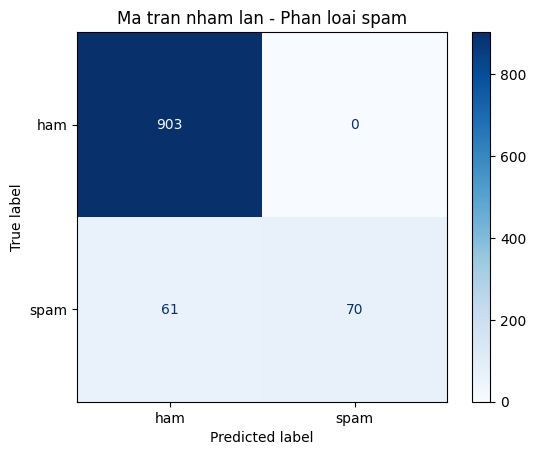


Noi dung: Congratulations! You won a free prize. Claim now!
Du doan: spam
Xac suat spam: 0.6557

Noi dung: Hello, can we meet tomorrow morning?
Du doan: ham
Xac suat spam: 0.0101

Noi dung: Urgent! Call now to receive your cash reward.
Du doan: spam
Xac suat spam: 0.5277


In [1]:

import io
import zipfile
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# 1. Tai du lieu UCI
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urllib.request.urlopen(url, timeout=60) as response:
    data_zip = response.read()

with zipfile.ZipFile(io.BytesIO(data_zip)) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f, sep="\t", header=None,
            names=["label", "text"],
            encoding="latin-1"
        )

# 2. Kiem tra va tien xu ly
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)

print("Kich thuoc:", df.shape)
print("So luong tung nhan:")
print(df["label"].value_counts())
print(df.head())

# 3. Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["y"],
    test_size=0.2, random_state=42, stratify=df["y"]
)

# 4. Chuyen van ban thanh TF-IDF va huan luyen
model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("nb", MultinomialNB())
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

# 5. Danh gia
print("\nAccuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("\nBao cao phan loai:")
print(classification_report(
    y_test, pred,
    target_names=["ham", "spam"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["ham", "spam"],
    cmap="Blues"
)
plt.title("Ma tran nham lan - Phan loai spam")
plt.show()

# 6. Thu du doan tin nhan moi
tin_nhan = [
    "Congratulations! You won a free prize. Claim now!",
    "Hello, can we meet tomorrow morning?",
    "Urgent! Call now to receive your cash reward."
]

ket_qua = model.predict(tin_nhan)
xac_suat = model.predict_proba(tin_nhan)[:, 1]

for text, label, prob in zip(tin_nhan, ket_qua, xac_suat):
    print("\nNoi dung:", text)
    print("Du doan:", "spam" if label == 1 else "ham")
    print("Xac suat spam:", round(prob, 4))
